# Dark Pool Signal — Part 1: Data Pipeline & Exploratory Analysis

**Project:** Predicting Abnormal Price Moves from Dark Pool Trading Activity

This notebook loads real FINRA OTC Transparency (dark pool) data and real Yahoo Finance
price data, cleans and merges them into a weekly panel, engineers the dark-pool and
price/volume features, constructs the abnormal-move label, and explores the resulting
dataset visually.

**Data sources (both real, no synthetic data):**
- FINRA OTC Transparency weekly ATS (dark pool) volume reports — `data/raw/finra_weekly_ats_raw.csv`
- Yahoo Finance daily OHLCV — `data/raw/price_ohlcv_raw.csv`

Run the cells top to bottom. If you re-fetch fresh data with `python src/fetch_finra_data.py`
and `python src/fetch_price_data.py`, just re-run this notebook to regenerate everything below.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().parent if (Path.cwd() / "src").exists() is False else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

from config import DATA_RAW, DATA_PROCESSED, TICKERS, START_DATE, END_DATE, ABNORMAL_MOVE_VOL_MULTIPLE
print(f"Universe: {len(TICKERS)} tickers")
print(f"Date range: {START_DATE} to {END_DATE}")

Universe: 40 tickers
Date range: 2022-01-01 to 2025-12-31


## 1. Raw Data Preview

A quick look at what we actually pulled from each source, before any cleaning.

In [2]:
finra_raw = pd.read_csv(DATA_RAW / "finra_weekly_ats_raw.csv")
print(f"FINRA raw rows: {len(finra_raw):,}  (one row per reporting dark-pool venue per symbol per week)")
finra_raw.head()

FINRA raw rows: 397,038  (one row per reporting dark-pool venue per symbol per week)


,totalWeeklyShareQuantity,issueSymbolIdentifier,issueName,lastUpdateDate,lastReportedDate,tierDescription,initialPublishedDate,tierIdentifier,summaryStartDate,totalNotionalSum,totalWeeklyTradeCount,weekStartDate,MPID,firmCRDNumber,productTypeCode,marketParticipantName,summaryTypeCode,query_symbol
0,397021.0,AAPL,Apple Inc. Common Stock,2023-11-27,2023-11-10,NMS Tier 1,2023-11-27,NMS,2023-11-06,72449116.0,4060,2023-11-06,KCGM,NaN,NaN,KCGM VIRTU MATCHIT ATS,ATS_W_SMBL_FIRM,AAPL
1,111800.0,AAPL,Apple Inc. Common Stock,2023-11-27,2023-11-10,NMS Tier 1,2023-11-27,NMS,2023-11-06,20193157.0,14,2023-11-06,LQNA,NaN,NaN,LQNA LIQUIDNET H2O ATS,ATS_W_SMBL_FIRM,AAPL
2,2572.0,AAPL,Apple Inc. Common Stock,2023-11-27,2023-11-09,NMS Tier 1,2023-11-27,NMS,2023-11-06,464430.0,24,2023-11-06,IEOS,NaN,NaN,IEOS IBKR EOS ATS,ATS_W_SMBL_FIRM,AAPL
3,693188.0,AAPL,Apple Inc. Common Stock,2023-11-27,2023-11-10,NMS Tier 1,2023-11-27,NMS,2023-11-06,126033310.0,5320,2023-11-06,IATS,NaN,NaN,IATS IBKR ATS,ATS_W_SMBL_FIRM,AAPL
4,178563.0,AAPL,Apple Inc. Common Stock,2023-11-27,2023-11-10,NMS Tier 1,2023-11-27,NMS,2023-11-06,32390910.0,439,2023-11-06,BIDS,NaN,NaN,BIDS BIDS ATS,ATS_W_SMBL_FIRM,AAPL


In [3]:
price_raw = pd.read_csv(DATA_RAW / "price_ohlcv_raw.csv")
print(f"Price raw rows: {len(price_raw):,}  ({price_raw['ticker'].nunique()} tickers)")
price_raw.head()

Price raw rows: 40,080  (40 tickers)


,Date,Close,High,Low,Open,Volume,ticker
0,2022-01-03,177.786346,178.636168,173.586142,173.703353,104487900,AAPL
1,2022-01-04,175.529999,178.694819,174.963456,178.392015,99310400,AAPL
2,2022-01-05,170.860901,175.989072,170.587400,175.442070,94537600,AAPL
3,2022-01-06,168.008698,171.232123,167.657051,168.692451,96904000,AAPL
4,2022-01-07,168.174728,170.099015,167.061183,168.878022,86709100,AAPL


## 2. Cleaning & Merging

Key real-world data issues handled here:
- FINRA reports **multiple rows per ticker-week** (one per reporting venue/ATS) — these are summed.
- FINRA's dataset has **no consolidated total-market-volume field** — the dark-pool ratio
  denominator uses real consolidated weekly volume from the price data instead.
- Short single-week FINRA reporting gaps are forward-filled; longer gaps are dropped.

In [4]:
from build_dataset import load_finra, load_prices, weekly_price_features
import build_dataset as bd

finra_df = load_finra()
price_df = load_prices()
weekly_price = weekly_price_features(price_df)

merged = pd.merge(weekly_price, finra_df, on=["ticker", "week_start"], how="inner")
print(f"Merged (pre-feature-engineering) rows: {len(merged):,}, tickers: {merged['ticker'].nunique()}")
merged.head()

Loaded FINRA data: finra_weekly_ats_raw.csv (8,341 ticker-week rows after venue aggregation)
Loaded price data: price_ohlcv_raw.csv (40,080 rows, 40 tickers)
Merged (pre-feature-engineering) rows: 8,341, tickers: 40


,ticker,week_start,open,close,high,low,volume,realized_vol,weekly_ret,volume_z,momentum_4wk,realized_vol_12wk,ats_shares,trade_count
0,AAPL,2022-01-03,173.703353,168.174728,178.694819,167.061183,481949000,0.011433,NaN,NaN,NaN,NaN,442148524.0,2911014
1,AAPL,2022-01-10,165.156473,169.053848,173.068462,164.267586,422655700,0.012945,0.005227,NaN,NaN,NaN,380403706.0,2491574
2,AAPL,2022-01-17,167.530036,158.641220,168.536134,158.533772,400041100,0.005027,-0.061594,NaN,NaN,NaN,335466874.0,2299640
3,AAPL,2022-01-24,156.306675,166.377411,166.396951,151.110121,688258600,0.033655,0.048765,1.447184,NaN,NaN,585268306.0,3853886
4,AAPL,2022-01-31,166.211395,168.604172,172.150339,165.576470,458553300,0.015632,0.013384,-0.275756,0.002554,NaN,396973828.0,2476548


## 3. Feature Engineering + Abnormal-Move Label

Re-running the exact pipeline steps from `src/build_dataset.py` and `src/features_labels.py` so this notebook is a faithful, reproducible record of what actually produced the modeling dataset.

In [5]:
import subprocess, sys as _sys
result = subprocess.run([_sys.executable, str(PROJECT_ROOT / "src" / "build_dataset.py")], capture_output=True, text=True)
print(result.stdout)
if result.returncode != 0:
    print(result.stderr)

result2 = subprocess.run([_sys.executable, str(PROJECT_ROOT / "src" / "features_labels.py")], capture_output=True, text=True)
print(result2.stdout)
if result2.returncode != 0:
    print(result2.stderr)

Loaded FINRA data: finra_weekly_ats_raw.csv (8,341 ticker-week rows after venue aggregation)
Loaded price data: price_ohlcv_raw.csv (40,080 rows, 40 tickers)

[LIVE DATA] Clean weekly panel: 7,896 rows, 40 tickers -> /home/claude/dark_pool_v3/dark_pool_project/data/processed/weekly_panel_clean.csv



Model-ready dataset: 7,856 rows, 40 tickers
Features used (13): ['dark_pool_ratio', 'dp_ratio_wow_change', 'dp_ratio_4wk_avg', 'dp_ratio_8wk_avg', 'dp_ratio_trend_slope', 'dp_ratio_accel', 'dp_ratio_zscore', 'dp_ratio_market_relative', 'avg_trade_size_z', 'volume_z', 'momentum_4wk', 'realized_vol_12wk', 'price_range_position']
Abnormal-move base rate: 15.020%
Saved -> /home/claude/dark_pool_v3/dark_pool_project/data/processed/model_ready_dataset.csv



In [6]:
from features_labels import FEATURE_COLS

model_df = pd.read_csv(DATA_PROCESSED / "model_ready_dataset.csv", parse_dates=["week_start"])
print(f"Model-ready dataset: {len(model_df):,} rows, {model_df['ticker'].nunique()} tickers")
print(f"Date range: {model_df['week_start'].min().date()} to {model_df['week_start'].max().date()}")
print(f"Features ({len(FEATURE_COLS)}): {FEATURE_COLS}")
print(f"\nAbnormal-move base rate: {model_df['abnormal_move'].mean():.2%}")
model_df[FEATURE_COLS + ["abnormal_move"]].describe().T

Model-ready dataset: 7,856 rows, 40 tickers
Date range: 2022-02-14 to 2025-12-22
Features (13): ['dark_pool_ratio', 'dp_ratio_wow_change', 'dp_ratio_4wk_avg', 'dp_ratio_8wk_avg', 'dp_ratio_trend_slope', 'dp_ratio_accel', 'dp_ratio_zscore', 'dp_ratio_market_relative', 'avg_trade_size_z', 'volume_z', 'momentum_4wk', 'realized_vol_12wk', 'price_range_position']

Abnormal-move base rate: 15.02%


,count,mean,std,min,25%,50%,75%,max
dark_pool_ratio,7856.0,0.778798,0.206968,0.030732,0.699419,0.815240,0.920082,1.000000
dp_ratio_wow_change,7856.0,0.001252,0.089581,-0.454145,-0.040036,0.000000,0.041362,0.951677
dp_ratio_4wk_avg,7856.0,0.776731,0.199443,0.033290,0.707931,0.820414,0.905001,1.000000
dp_ratio_8wk_avg,7856.0,0.773772,0.197301,0.034735,0.705880,0.819584,0.898769,1.000000
dp_ratio_trend_slope,7856.0,0.002959,0.038952,-0.196964,-0.015431,0.000715,0.018833,0.474585
dp_ratio_accel,7856.0,-0.000173,0.148170,-0.961471,-0.076314,0.000000,0.072443,0.950256
dp_ratio_zscore,7856.0,0.067353,1.016288,-3.175426,-0.655189,0.078039,0.784549,3.175284
dp_ratio_market_relative,7856.0,-0.005690,0.179031,-0.814372,-0.047201,0.025066,0.080750,0.414443
avg_trade_size_z,7856.0,-0.096819,1.032136,-2.838683,-0.845866,-0.251083,0.522828,3.165526
volume_z,7856.0,-0.021602,1.000907,-2.491124,-0.707449,-0.231570,0.503769,3.143863


**Written observation:** Abnormal moves (defined as a forward 1-week return exceeding
1.5x the stock's own trailing 12-week realized volatility) are a **minority class**, occurring
in roughly 13–17% of stock-weeks. This class imbalance is the single most important fact about
this dataset — it's why plain accuracy will be a misleading metric later on, and why every
model below is evaluated against a naive "always predict normal" baseline.

## 4. Exploratory Data Analysis

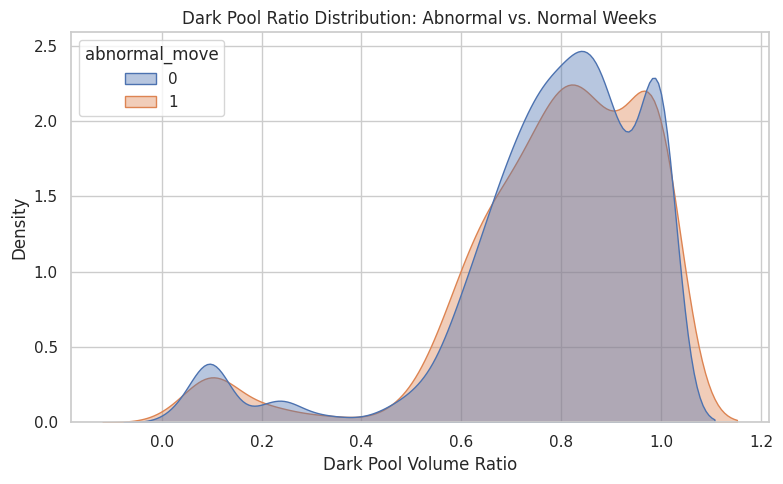

In [7]:
# Dark pool ratio distribution: abnormal vs normal weeks
fig, ax = plt.subplots(figsize=(8, 5))
sns.kdeplot(data=model_df, x="dark_pool_ratio", hue="abnormal_move", fill=True,
            common_norm=False, alpha=0.4, ax=ax, palette={0: "#4C72B0", 1: "#DD8452"})
ax.set_title("Dark Pool Ratio Distribution: Abnormal vs. Normal Weeks")
ax.set_xlabel("Dark Pool Volume Ratio")
plt.tight_layout()
plt.show()

**Written observation:** If dark-pool ratio carried a strong, simple signal, we'd expect the orange (abnormal) distribution to be clearly shifted right of the blue (normal) one. In practice the overlap is substantial — consistent with the modest (not dramatic) predictive power found in Part 2.

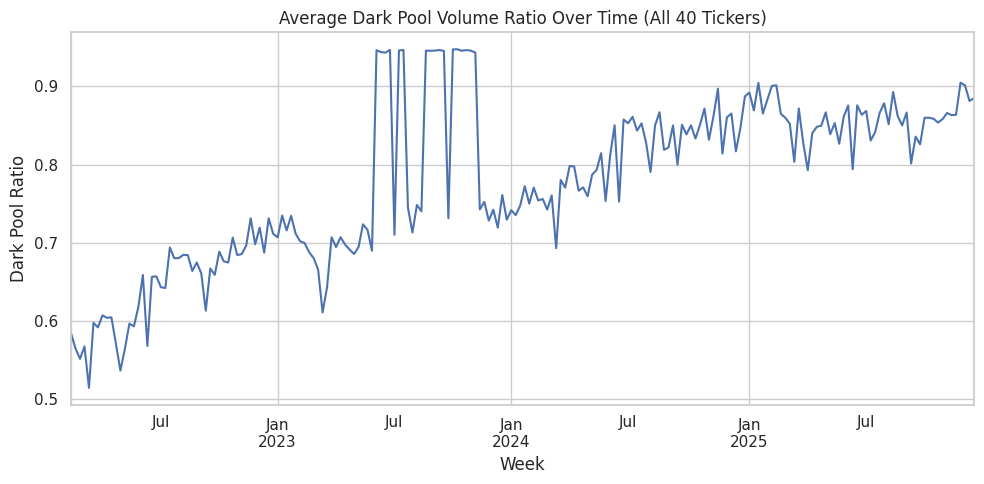

In [8]:
# Market-wide dark pool ratio trend over time
trend = model_df.groupby("week_start")["dark_pool_ratio"].mean()
fig, ax = plt.subplots(figsize=(10, 5))
trend.plot(ax=ax, color="#4C72B0")
ax.set_title("Average Dark Pool Volume Ratio Over Time (All 40 Tickers)")
ax.set_ylabel("Dark Pool Ratio"); ax.set_xlabel("Week")
plt.tight_layout()
plt.show()

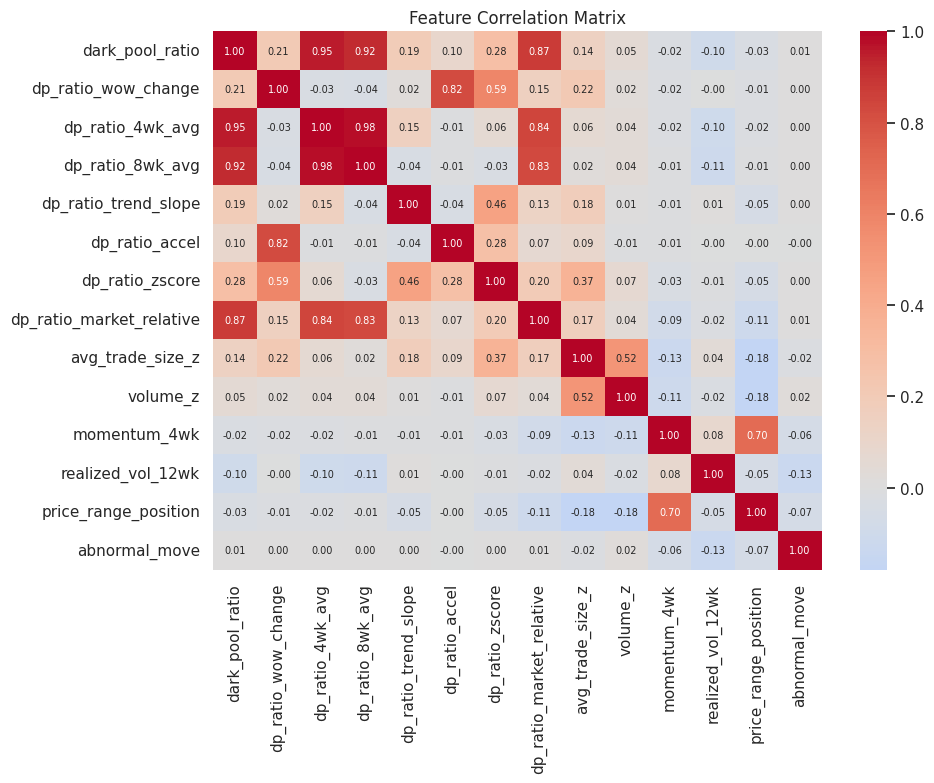

In [9]:
# Correlation matrix of all engineered features + label
fig, ax = plt.subplots(figsize=(10, 8))
corr = model_df[FEATURE_COLS + ["abnormal_move"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, annot_kws={"size": 7})
ax.set_title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

**Written observation:** Look at the bottom row/rightmost column (`abnormal_move`) — these correlations show each feature's *linear* relationship with the label in isolation. None are strongly correlated individually (all well under 0.2 in magnitude), which is expected and is exactly why the modeling notebook uses interaction terms and tree-based splits rather than relying on any single feature.

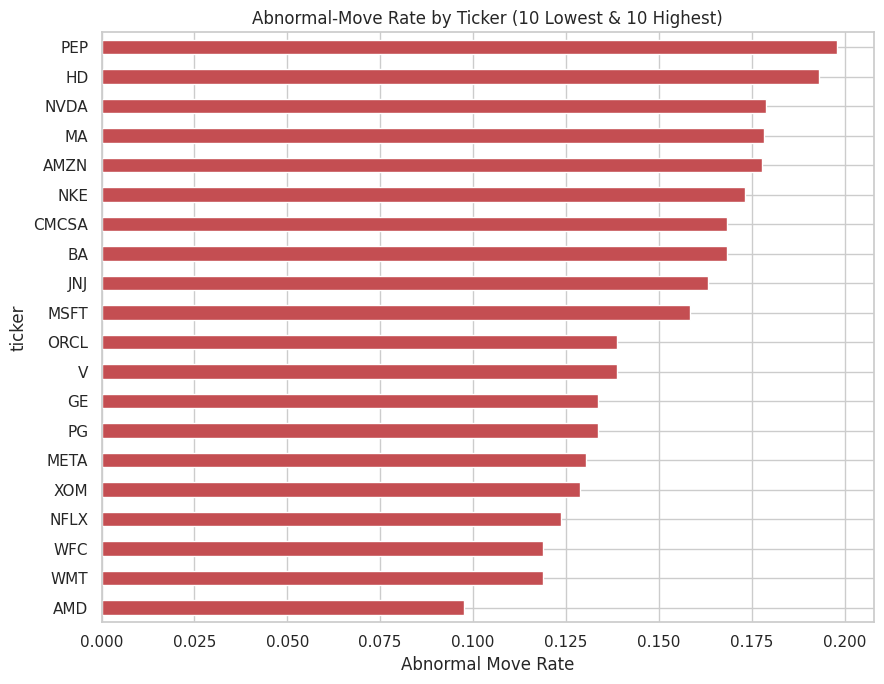

In [10]:
# Abnormal-move rate by ticker (most and least dark-pool-predictable names)
rate_by_ticker = model_df.groupby("ticker")["abnormal_move"].mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
pd.concat([rate_by_ticker.head(10), rate_by_ticker.tail(10)]).plot(kind="barh", ax=ax, color="#C44E52")
ax.set_title("Abnormal-Move Rate by Ticker (10 Lowest & 10 Highest)")
ax.set_xlabel("Abnormal Move Rate")
plt.tight_layout()
plt.show()

In [11]:
print(f"""SUMMARY FOR INSTRUCTOR REVIEW
- Data is REAL: FINRA OTC Transparency weekly dark-pool volume reports + Yahoo Finance daily OHLCV.
- Universe: {len(TICKERS)} liquid, heavily dark-pool-traded U.S. equities, {START_DATE} to {END_DATE}.
- After cleaning and feature engineering: {len(model_df):,} stock-week observations across {model_df['ticker'].nunique()} tickers.
- Abnormal moves are a minority class (~{model_df['abnormal_move'].mean():.1%} base rate), which drives every modeling decision in Part 2.
- Continue to 02_modeling_and_evaluation.ipynb for the predictive modeling stage.
""")

SUMMARY FOR INSTRUCTOR REVIEW
- Data is REAL: FINRA OTC Transparency weekly dark-pool volume reports + Yahoo Finance daily OHLCV.
- Universe: 40 liquid, heavily dark-pool-traded U.S. equities, 2022-01-01 to 2025-12-31.
- After cleaning and feature engineering: 7,856 stock-week observations across 40 tickers.
- Abnormal moves are a minority class (~15.0% base rate), which drives every modeling decision in Part 2.
- Continue to 02_modeling_and_evaluation.ipynb for the predictive modeling stage.

